# 06 · New York Taxi Fares — Final Course Project

**Dataset:** [New York City Taxi Fare Prediction](https://www.kaggle.com/datasets/dansbecker/new-york-city-taxi-fare-prediction) — a sample of 50,000 yellow-cab trips in New York, 2009–2015.

**Target:** `fare_amount` — the price of the trip in dollars (meter plus tolls, without the tip).

**Why it matters.** A ride-hailing app shows the passenger a price *before* the trip, when only the pickup and drop-off points, the time and the number of passengers are known. The more accurate that forecast, the fewer disappointed customers and arguments about the fare.

**Why this dataset.** It contains everything real work does: dirty data (zero and swapped coordinates, negative fares), heavy feature engineering (distance, airports and rush hour have to be derived from raw coordinates and timestamps), rules that change over time (the September 2012 tariff increase) and a metric a business can read — dollars.

**Plan**

1. Loading and preprocessing
2. New features from coordinates and time
3. Train / validation / test split
4. Exploratory analysis and charts (on the training set only)
5. Statistical hypothesis tests
6. Interim report
7. Framing the task and choosing a metric
8. Dummy baselines and ML models, hyperparameters tuned on validation
9. Final forecast on the test set and error analysis
10. Conclusions: is machine learning needed here?

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import ParameterGrid
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

warnings.filterwarnings('ignore', category=FutureWarning)

RANDOM_STATE = 42
ALPHA = 0.05  # significance level for every hypothesis test

# Chart palette: fixed colour order, muted axes and grid
BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
INK, INK_2, MUTED, GRID, SURFACE = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#fcfcfb'

plt.rcParams.update({
    'figure.facecolor': SURFACE,
    'axes.facecolor': SURFACE,
    'axes.edgecolor': '#c3c2b7',
    'axes.labelcolor': INK_2,
    'axes.titlecolor': INK,
    'axes.titlesize': 12,
    'axes.titleweight': 'bold',
    'axes.titlelocation': 'left',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.color': GRID,
    'grid.linewidth': 0.6,
    'axes.axisbelow': True,
    'xtick.color': MUTED,
    'ytick.color': MUTED,
    'text.color': INK,
    'legend.frameon': False,
    'axes.prop_cycle': plt.cycler(color=[BLUE, ORANGE, AQUA]),
    'figure.dpi': 100,
})
pd.set_option('display.float_format', '{:.3f}'.format)
pd.set_option('display.max_columns', 50)

## 1. Loading and first look at the data

In [2]:
raw = pd.read_csv('../data/nyc_taxi_fare.csv')
print(f'Shape: {raw.shape[0]} rows x {raw.shape[1]} columns')
raw.head()

Shape: 50000 rows x 8 columns


,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,2009-06-15 17:26:21.0000001,4.500,2009-06-15 17:26:21 UTC,-73.844,40.721,-73.842,40.712,1
1,2010-01-05 16:52:16.0000002,16.900,2010-01-05 16:52:16 UTC,-74.016,40.711,-73.979,40.782,1
2,2011-08-18 00:35:00.00000049,5.700,2011-08-18 00:35:00 UTC,-73.983,40.761,-73.991,40.751,2
3,2012-04-21 04:30:42.0000001,7.700,2012-04-21 04:30:42 UTC,-73.987,40.733,-73.992,40.758,1
4,2010-03-09 07:51:00.000000135,5.300,2010-03-09 07:51:00 UTC,-73.968,40.768,-73.957,40.784,1


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   key                50000 non-null  str    
 1   fare_amount        50000 non-null  float64
 2   pickup_datetime    50000 non-null  str    
 3   pickup_longitude   50000 non-null  float64
 4   pickup_latitude    50000 non-null  float64
 5   dropoff_longitude  50000 non-null  float64
 6   dropoff_latitude   50000 non-null  float64
 7   passenger_count    50000 non-null  int64  
dtypes: float64(5), int64(1), str(2)
memory usage: 3.1 MB


In [4]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
fare_amount,50000.000,11.364,9.686,-5.000,6.000,8.500,12.500,200.000
pickup_longitude,50000.000,-72.510,10.394,-75.424,-73.992,-73.982,-73.967,40.783
pickup_latitude,50000.000,39.934,6.225,-74.007,40.735,40.753,40.767,401.083
dropoff_longitude,50000.000,-72.505,10.408,-84.654,-73.991,-73.980,-73.964,40.851
dropoff_latitude,50000.000,39.926,6.015,-74.006,40.734,40.753,40.768,43.415
passenger_count,50000.000,1.668,1.289,0.000,1.000,1.000,2.000,6.000


In [5]:
print('Missing values per column:')
print(raw.isna().sum())
print('\nFull duplicates:', raw.duplicated().sum())
print('Duplicates ignoring the key:', raw.drop(columns='key').duplicated().sum())
print('Unique keys:', raw['key'].nunique())

Missing values per column:
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
dtype: int64

Full duplicates: 0
Duplicates ignoring the key: 0
Unique keys: 50000


**What is visible immediately**

* No missing values, no duplicates, and `key` is unique — it identifies the trip and will not be a feature.
* `pickup_datetime` is a string in UTC. It has to become a timestamp in **New York local time**, otherwise "rush hour" shifts by 4–5 hours.
* The coordinates are clearly dirty: the minimum longitude is near 0 and the maximum latitude is 401 — some trips have zero coordinates or latitude and longitude swapped.
* `fare_amount` reaches 200 dollars, and the minimum needs checking: the drop charge alone is 2.50 dollars, so no trip can cost less.

## 2. Preprocessing

Cleaning rules:

1. **Coordinates** of pickup and drop-off must lie in a rectangle around New York (longitude −74.3…−72.9, latitude 40.5…41.8). That covers all five boroughs and the three airports, including EWR in New Jersey. Zeros and swapped latitude/longitude fall outside it.
2. **The fare** cannot be below the 2.50 dollar drop charge. A zero or negative fare is a recording error or a refund, not a trip.

Rows with `passenger_count = 0` stay: that is a driver's input error, while their coordinates and fare are fine, and the passenger count does not affect the tariff (tested as a hypothesis below).

In [6]:
df = raw.copy()

# A string like '2009-06-15 17:26:21 UTC' -> New York local time without a timezone
df['pickup_datetime'] = (
    pd.to_datetime(df['pickup_datetime'], format='%Y-%m-%d %H:%M:%S UTC', utc=True)
    .dt.tz_convert('America/New_York')
    .dt.tz_localize(None)
)

LON_RANGE = (-74.3, -72.9)
LAT_RANGE = (40.5, 41.8)

in_nyc = (
    df['pickup_longitude'].between(*LON_RANGE)
    & df['dropoff_longitude'].between(*LON_RANGE)
    & df['pickup_latitude'].between(*LAT_RANGE)
    & df['dropoff_latitude'].between(*LAT_RANGE)
)
valid_fare = df['fare_amount'] >= 2.5

report = pd.Series({
    'coordinates outside New York': (~in_nyc).sum(),
    '  of them zero coordinates': (~in_nyc & (df['pickup_longitude'] == 0)).sum(),
    'fare below 2.50 $': (~valid_fare).sum(),
    'removed in total': (~(in_nyc & valid_fare)).sum(),
})
print(report.to_string())

df = df[in_nyc & valid_fare].reset_index(drop=True)
print(f'\n{len(df)} rows left ({len(df) / len(raw):.1%} of the original)')

coordinates outside New York    1062
  of them zero coordinates       955
fare below 2.50 $                 10
removed in total                1071

48929 rows left (97.9% of the original)


## 3. New features

A taxi fare is the drop charge plus payment for distance and for time spent in traffic, plus surcharges and the special airport tariff. The features mirror that logic:

* `distance_km` — straight-line distance between pickup and drop-off. The real route is unknown, and a straight line is the best approximation.
* `delta_lat`, `delta_lon` — the north–south and east–west displacement. They show *where* the trip went: moving east or west often means crossing a river.
* `year`, `month`, `weekday`, `hour`, `is_weekend` — surcharges and traffic depend on the hour and the day, and prices rise year over year.
* `new_tariff` — the trip happened after 4 September 2012, when the tariff was raised.
* `jfk_trip` — pickup or drop-off within 2 km of JFK airport: a flat fare and tolls apply there.

The original coordinates and `passenger_count` go into the model as well.

Only the pickup time is known, which is how it should be: the price is shown *before* the trip, so the trip duration cannot be used — that would leak the answer.

None of the features use the fare, so they can be built before the split.

In [7]:
TARIFF_CHANGE = pd.Timestamp('2012-09-04')
POINTS = {
    'jfk': (40.6413, -73.7781),
    'lga': (40.7769, -73.8740),
    'ewr': (40.6895, -74.1745),
    'midtown': (40.7580, -73.9855),
}


def haversine_km(lat1, lon1, lat2, lon2):
    # Distance along the Earth's surface between two points, km
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2)
    return 2 * 6371 * np.arcsin(np.sqrt(a))


def add_features(data):
    out = data.copy()
    plat, plon = out['pickup_latitude'], out['pickup_longitude']
    dlat, dlon = out['dropoff_latitude'], out['dropoff_longitude']

    # Straight-line distance and displacement in latitude and longitude
    out['distance_km'] = haversine_km(plat, plon, dlat, dlon)
    out['delta_lat'] = (dlat - plat).abs()
    out['delta_lon'] = (dlon - plon).abs()

    # Trip time (local)
    dt = out['pickup_datetime']
    out['year'] = dt.dt.year
    out['month'] = dt.dt.month
    out['weekday'] = dt.dt.weekday
    out['hour'] = dt.dt.hour
    out['is_weekend'] = (out['weekday'] >= 5).astype(int)
    out['new_tariff'] = (dt >= TARIFF_CHANGE).astype(int)

    # A JFK trip: pickup or drop-off within 2 km of the airport
    jfk_lat, jfk_lon = POINTS['jfk']
    to_jfk = np.minimum(haversine_km(plat, plon, jfk_lat, jfk_lon),
                        haversine_km(dlat, dlon, jfk_lat, jfk_lon))
    out['jfk_trip'] = (to_jfk < 2).astype(int)
    return out


df = add_features(df)
df[['distance_km', 'delta_lat', 'delta_lon', 'hour', 'weekday', 'new_tariff', 'jfk_trip']].describe().T

,count,mean,std,min,25%,50%,75%,max
distance_km,48929.000,3.353,3.897,0.000,1.263,2.159,3.938,104.035
delta_lat,48929.000,0.021,0.025,0.000,0.007,0.014,0.027,0.869
delta_lon,48929.000,0.023,0.036,0.000,0.006,0.013,0.024,0.874
hour,48929.000,11.777,5.856,0.000,7.000,12.000,17.000,23.000
weekday,48929.000,2.979,1.913,0.000,1.000,3.000,5.000,6.000
new_tariff,48929.000,0.427,0.495,0.000,0.000,0.000,1.000,1.000
jfk_trip,48929.000,0.021,0.144,0.000,0.000,0.000,0.000,1.000


In [8]:
# The most expensive trips: does the fare match the distance?
top_fares = df.nlargest(15, 'fare_amount')
zero_dist = df['distance_km'] < 0.1
print('Of the 15 most expensive trips, shorter than 1 km:', (top_fares['distance_km'] < 1).sum())
print('Trips with zero distance (< 100 m):', zero_dist.sum())
print('  of them above 30 $:', (zero_dist & (df['fare_amount'] > 30)).sum())

top_fares[['pickup_datetime', 'fare_amount', 'distance_km', 'pickup_latitude',
           'pickup_longitude', 'dropoff_latitude', 'dropoff_longitude', 'jfk_trip']]

Of the 15 most expensive trips, shorter than 1 km: 8
Trips with zero distance (< 100 m): 833
  of them above 30 $: 109


,pickup_datetime,fare_amount,distance_km,pickup_latitude,pickup_longitude,dropoff_latitude,dropoff_longitude,jfk_trip
27770,2012-02-25 22:24:00,200.000,0.000,41.391,-73.955,41.391,-73.955,0
1450,2009-08-07 17:49:13,165.000,0.028,41.032,-73.633,41.033,-73.634,0
43029,2014-10-31 23:35:37,165.000,4.950,40.754,-73.932,40.798,-73.920,0
45214,2013-05-13 07:18:00,160.000,1.372,41.009,-73.645,41.021,-73.641,0
25468,2014-08-14 16:22:14,149.000,0.001,40.730,-73.855,40.730,-73.855,0
41847,2010-05-09 14:35:44,143.000,0.000,40.769,-73.351,40.769,-73.351,0
32784,2014-02-21 21:44:00,136.000,44.747,40.757,-73.990,41.147,-73.861,0
24664,2013-12-16 05:56:58,135.000,0.367,40.780,-73.425,40.783,-73.423,0
36412,2009-12-03 18:40:00,128.610,0.081,40.755,-73.996,40.755,-73.995,0
20434,2010-07-17 13:34:16,120.000,0.000,40.956,-73.740,40.956,-73.740,0


**The most expensive trips are mostly coordinate anomalies.**

Eight of the fifteen most expensive trips are shorter than a kilometre: for 200 dollars a passenger "travelled" 0.3 metres. Many of them start outside the city, in Westchester and on Long Island.

These are most likely out-of-town trips at an agreed price: the meter was off and the drop-off point was recorded as equal to the pickup point. The fare is real, but the coordinates do not describe the trip, so it cannot be predicted.

I do not remove these rows: they cannot be removed from the test set (at prediction time the fare is unknown), and in training they honestly reflect the data. Their share of the error is analysed in section 14.

## 4. Splitting the data

The split is by time rather than random: the model will be applied to future trips, so it has to be checked on a period it has not seen.

* **train** — 2009–2013: model training and exploratory analysis.
* **valid** — 2014: model comparison and hyperparameter tuning.
* **test** — the first half of 2015: a single final measurement.

The 2012 tariff increase falls inside train, so the model sees both tariffs.

In [9]:
year = df['pickup_datetime'].dt.year
train = df[year <= 2013].reset_index(drop=True)
valid = df[year == 2014].reset_index(drop=True)
test = df[year == 2015].reset_index(drop=True)

split_info = pd.DataFrame({
    'rows': [len(train), len(valid), len(test)],
    'share': [len(train) / len(df), len(valid) / len(df), len(test) / len(df)],
    'from': [s['pickup_datetime'].min().date() for s in (train, valid, test)],
    'to': [s['pickup_datetime'].max().date() for s in (train, valid, test)],
}, index=['train', 'valid', 'test'])
split_info

,rows,share,from,to
train,38160,0.780,2008-12-31,2013-12-31
valid,7391,0.151,2014-01-01,2014-12-31
test,3378,0.069,2015-01-01,2015-06-30


Six trips dated 31 December 2008 ended up in the training set: in UTC that is already 1 January 2009, but in local time it is New Year's Eve. This is not an error but a consequence of the timezone conversion.

## 5. Exploratory analysis (training set)

In [10]:
# Fare per kilometre only makes sense for trips with a non-zero distance
train['fare_per_km'] = np.where(train['distance_km'] > 0.1,
                                train['fare_amount'] / train['distance_km'], np.nan)

train[['fare_amount', 'distance_km', 'fare_per_km', 'passenger_count']].describe(
    percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
).T

,count,mean,std,min,5%,25%,50%,75%,95%,99%,max
fare_amount,38160.000,10.858,9.093,2.500,4.100,5.700,8.100,12.100,28.500,49.800,200.000
distance_km,38160.000,3.319,3.919,0.000,0.556,1.257,2.149,3.892,9.921,20.203,104.035
fare_per_km,37457.000,4.387,5.361,0.025,2.149,2.862,3.679,4.850,7.960,14.757,428.190
passenger_count,38160.000,1.668,1.278,0.000,1.000,1.000,1.000,2.000,5.000,6.000,6.000


In [11]:
print('Fare skewness:', round(train['fare_amount'].skew(), 2))
print('Trips with zero distance (< 100 m):', (train['distance_km'] < 0.1).sum())
print('Trips to or from JFK:', train['jfk_trip'].sum())
print('\nMost frequent fares:')
print(train['fare_amount'].value_counts().head(8).to_string())

Fare skewness: 3.63
Trips with zero distance (< 100 m): 703
Trips to or from JFK: 745

Most frequent fares:
fare_amount
6.500    1932
4.500    1689
8.500    1415
5.300    1412
6.100    1410
5.700    1405
4.900    1363
6.900    1284


In [12]:
by_year = train.groupby('year').agg(
    trips=('fare_amount', 'size'),
    mean_fare=('fare_amount', 'mean'),
    median_fare=('fare_amount', 'median'),
    median_km=('distance_km', 'median'),
)
by_year

,trips,mean_fare,median_fare,median_km
year,,,,
2008,6,11.867,10.600,3.276
2009,7612,10.049,7.700,2.061
2010,7445,10.157,7.700,2.104
2011,7622,10.460,7.700,2.182
2012,7812,11.176,8.500,2.174
2013,7663,12.415,9.500,2.223


**Interim observations**

* The fare is heavily right-skewed: half of the trips cost less than 8 dollars, but the tail reaches 200. That is why the mean is above the median.
* A typical trip is short — around 2 km, which is Manhattan.
* The most frequent fares (4.50, 6.50, 8.50 dollars) are multiples of the meter step: the tariff shapes the price.
* Some trips have zero distance. For those, distance says nothing about the fare.
* The mean fare grows year by year while the distance barely changes — so it is the tariff itself that is getting more expensive.

## 6. Charts

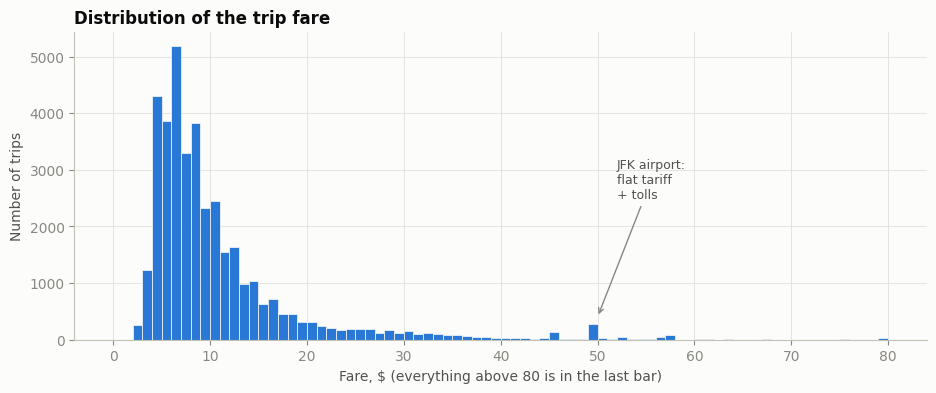

In [13]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.hist(train['fare_amount'].clip(upper=80), bins=np.arange(0, 81, 1),
        color=BLUE, edgecolor=SURFACE, linewidth=0.5)
ax.set(title='Distribution of the trip fare', xlabel='Fare, $ (everything above 80 is in the last bar)',
       ylabel='Number of trips')
ax.annotate('JFK airport:\nflat tariff\n+ tolls', xy=(50, 400), xytext=(52, 2500),
            color=INK_2, fontsize=9, arrowprops=dict(arrowstyle='->', color=MUTED))
plt.show()

The fare distribution is strongly right-skewed: most trips cost 4–12 dollars, and rare expensive trips form a long tail. On the right there is a separate bump around 45–57 dollars — the flat fare to JFK airport plus tolls.

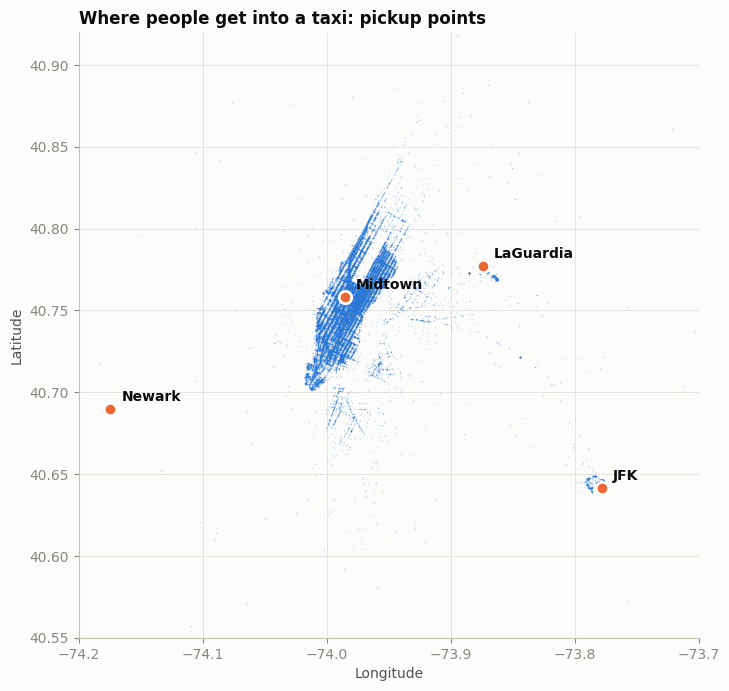

In [14]:
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(train['pickup_longitude'], train['pickup_latitude'],
           s=1, alpha=0.25, color=BLUE, linewidths=0)
for name, label in [('jfk', 'JFK'), ('lga', 'LaGuardia'), ('ewr', 'Newark'), ('midtown', 'Midtown')]:
    lat, lon = POINTS[name]
    ax.scatter(lon, lat, s=80, color=ORANGE, edgecolor=SURFACE, linewidth=2, zorder=3)
    ax.annotate(label, (lon, lat), xytext=(8, 6), textcoords='offset points',
                color=INK, fontsize=10, fontweight='bold')
ax.set(title='Where people get into a taxi: pickup points', xlabel='Longitude', ylabel='Latitude',
       xlim=(-74.2, -73.7), ylim=(40.55, 40.92))
ax.set_aspect(1 / np.cos(np.radians(40.75)))  # so that the map is not stretched
plt.show()

The pickup points draw the map of New York by themselves. Most trips start in Manhattan, and separate clusters are visible at the airports. So the coordinates and the `jfk_trip` flag should help the model.

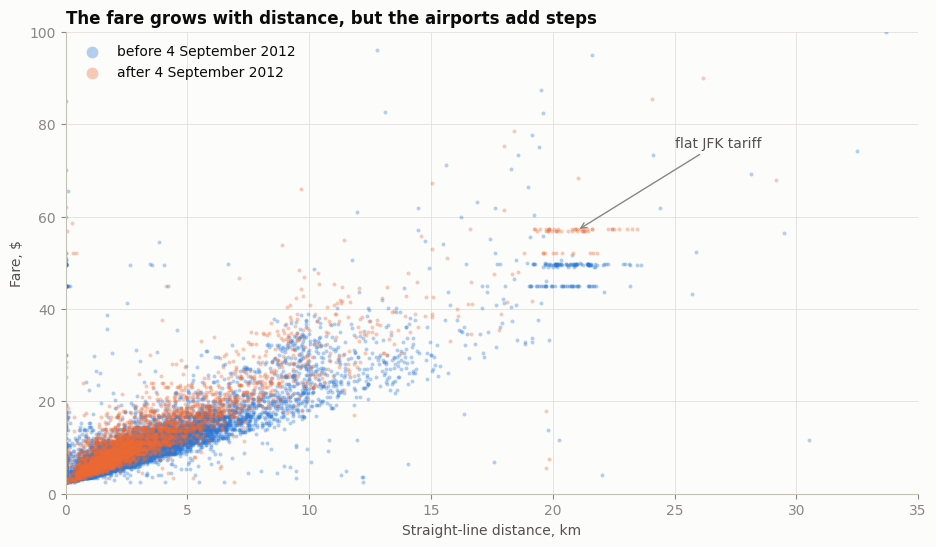

Pearson correlation fare/distance: 0.766


In [15]:
fig, ax = plt.subplots(figsize=(11, 6))
sample = train.sample(15000, random_state=RANDOM_STATE)
for flag, color, label in [(0, BLUE, 'before 4 September 2012'), (1, ORANGE, 'after 4 September 2012')]:
    part = sample[sample['new_tariff'] == flag]
    ax.scatter(part['distance_km'], part['fare_amount'], s=8, alpha=0.35,
               color=color, label=label, linewidths=0)
ax.set(title='The fare grows with distance, but the airports add steps',
       xlabel='Straight-line distance, km', ylabel='Fare, $', xlim=(0, 35), ylim=(0, 100))
ax.legend(markerscale=3, loc='upper left')
ax.annotate('flat JFK tariff', xy=(21, 57), xytext=(25, 75),
            color=INK_2, fontsize=10, arrowprops=dict(arrowstyle='->', color=MUTED))
plt.show()

print('Pearson correlation fare/distance:', round(train[['fare_amount', 'distance_km']].corr().iloc[0, 1], 3))

The link between fare and distance is strong and almost linear. The orange points (the new tariff) lie above the blue ones — the slope after September 2012 is steeper. Two horizontal bands around 50 and 57 dollars at distances of 18–25 km are clearly visible: those are JFK trips, where the fare does not depend on distance. There is also noise at zero on the x axis: trips with zero distance and a non-zero fare.

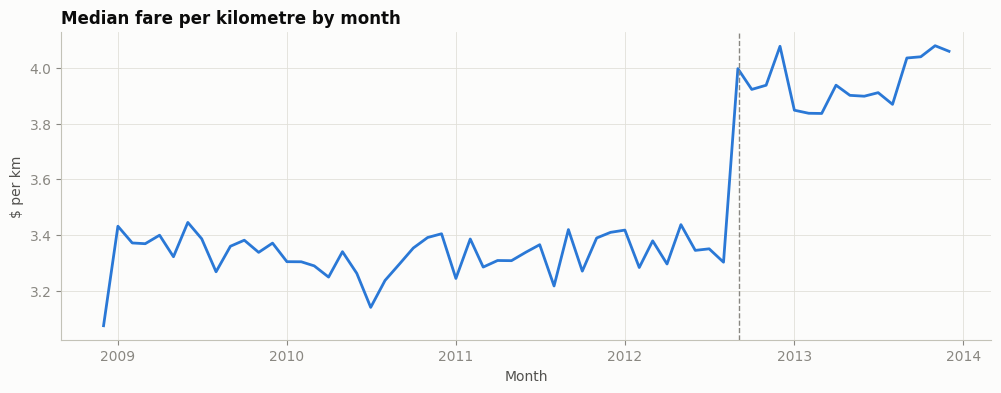

In [16]:
# Median fare per km by month for ordinary city trips (1–10 km, excluding JFK)
city = train[train['distance_km'].between(1, 10) & (train['jfk_trip'] == 0)]
monthly = city.set_index('pickup_datetime')['fare_per_km'].resample('MS').median()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(monthly.index, monthly.values, color=BLUE, linewidth=2)
ax.axvline(TARIFF_CHANGE, color=MUTED, linestyle='--', linewidth=1)
ax.set(title='Median fare per kilometre by month', xlabel='Month', ylabel='$ per km')
plt.show()

**The main finding over time:** the price per kilometre rose as a step in September 2012, and there were no further jumps. Prices did not drift gradually — they changed by a decision of the city. That makes the `new_tariff` feature more useful than `year` alone.

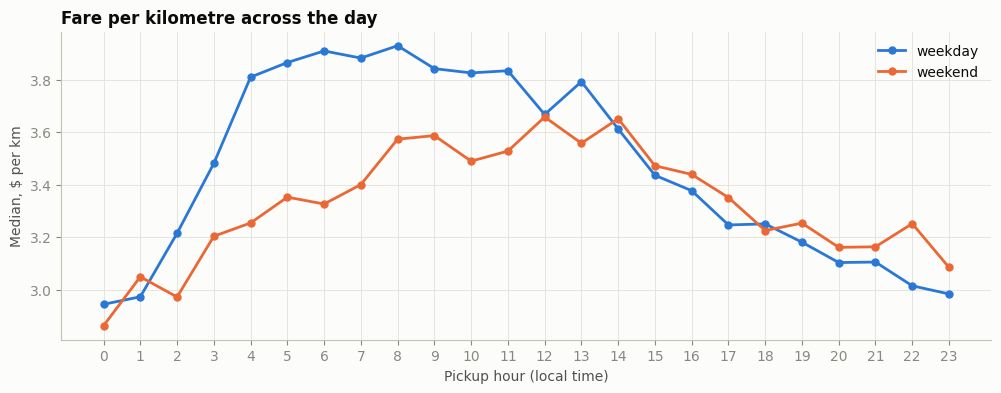

In [17]:
hourly = (city.assign(day=np.where(city['is_weekend'] == 1, 'weekend', 'weekday'))
          .groupby(['day', 'hour'])['fare_per_km'].median().unstack(0))

fig, ax = plt.subplots(figsize=(12, 4))
for col, color in [('weekday', BLUE), ('weekend', ORANGE)]:
    ax.plot(hourly.index, hourly[col], color=color, linewidth=2, marker='o', markersize=5, label=col)
ax.set(title='Fare per kilometre across the day', xlabel='Pickup hour (local time)',
       ylabel='Median, $ per km', xticks=range(0, 24))
ax.legend()
plt.show()

* On weekdays a kilometre is most expensive in the morning and early afternoon and gets cheaper towards the evening. The New York meter also charges for time spent in traffic, so slow morning traffic makes each kilometre more expensive.
* The minimum is late evening and night.
* At weekends the curve is lower and flatter, because there is no morning traffic.

The dependence on the hour is non-linear and differs between weekdays and weekends. A linear model will not capture it; trees will.

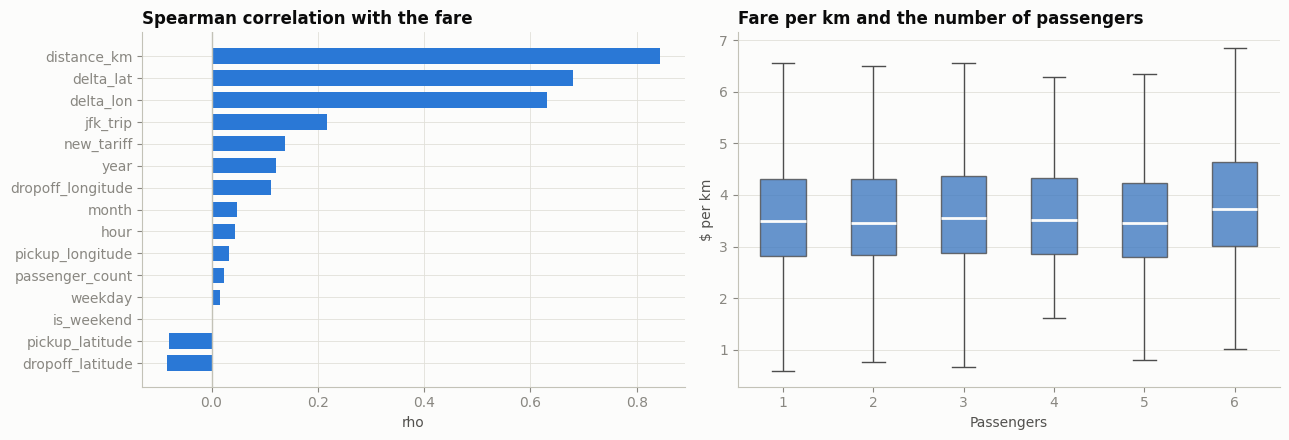

Spearman correlation fare/distance: 0.844


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# How the features relate to the fare
num_features = ['distance_km', 'delta_lat', 'delta_lon', 'jfk_trip', 'year', 'new_tariff',
                'hour', 'weekday', 'is_weekend', 'month', 'passenger_count',
                'pickup_latitude', 'pickup_longitude', 'dropoff_latitude', 'dropoff_longitude']
spearman = (train[num_features + ['fare_amount']].corr(method='spearman')['fare_amount']
            .drop('fare_amount').sort_values())
axes[0].barh(spearman.index, spearman.values, color=BLUE, height=0.7)
axes[0].axvline(0, color='#c3c2b7', linewidth=1)
axes[0].set(title='Spearman correlation with the fare', xlabel='rho')

sns.boxplot(data=city[city['passenger_count'].between(1, 6)], x='passenger_count', y='fare_per_km',
            color=BLUE, showfliers=False, width=0.5, ax=axes[1],
            boxprops=dict(alpha=0.8), medianprops=dict(color=SURFACE, linewidth=2))
axes[1].set(title='Fare per km and the number of passengers', xlabel='Passengers', ylabel='$ per km')

plt.tight_layout()
plt.show()

print('Spearman correlation fare/distance:', round(spearman['distance_km'], 3))

* The fare is linked most strongly to distance, then to the `delta_lat` and `delta_lon` displacements and the JFK flag. `new_tariff` and `year` give a weak but non-zero link. The raw coordinates have almost no correlation with the fare on their own: they are useful in combination (which part of the city the trip is in), and a model can only find that non-linearly.
* The number of passengers barely affects the fare per kilometre — the boxes on the right-hand chart are practically identical.
* `distance_km`, `delta_lat` and `delta_lon` correlate strongly with each other. For trees that is not a problem.

## 7. Hypothesis tests

The fare is asymmetric with a heavy tail, so I use **non-parametric tests**: Mann–Whitney for two groups and Kruskal–Wallis for several. Everywhere the data is ordinary city trips of 1–10 km without JFK. The significance level is α = 0.05.

In [19]:
def mann_whitney(a, b, alternative, name_a, name_b):
    stat, p = stats.mannwhitneyu(a, b, alternative=alternative)
    print(f'{name_a}: median {np.median(a):.3f} $/km (n={len(a)})')
    print(f'{name_b}: median {np.median(b):.3f} $/km (n={len(b)})')
    print(f'U = {stat:.0f}, p-value = {p:.2e} ->',
          'reject H0' if p < ALPHA else 'do not reject H0')


print('H1. The September 2012 increase made a kilometre more expensive')
print('H0: the fare per km is the same before and after; H1: it is higher after\n')
mann_whitney(city.loc[city['new_tariff'] == 1, 'fare_per_km'],
             city.loc[city['new_tariff'] == 0, 'fare_per_km'],
             'greater', 'after', 'before')

H1. The September 2012 increase made a kilometre more expensive
H0: the fare per km is the same before and after; H1: it is higher after

after: median 3.956 $/km (n=8003)
before: median 3.339 $/km (n=21888)
U = 115747421, p-value = 0.00e+00 -> reject H0


In [20]:
# The hypothesis was set in advance, from the tariff: on weekdays from 16:00 to 20:00 a 1 $ surcharge applies
print('H2. The fare per km in the weekday rush hour (16–20) is higher than at night (0–5)')
print('H0: no difference; H1: higher in the rush hour\n')
weekday_city = city[city['is_weekend'] == 0]
mann_whitney(weekday_city.loc[weekday_city['hour'].between(16, 19), 'fare_per_km'],
             weekday_city.loc[weekday_city['hour'].between(0, 5), 'fare_per_km'],
             'greater', 'rush hour', 'night')

H2. The fare per km in the weekday rush hour (16–20) is higher than at night (0–5)
H0: no difference; H1: higher in the rush hour

rush hour: median 3.274 $/km (n=4872)
night: median 3.556 $/km (n=4376)
U = 9136750, p-value = 1.00e+00 -> do not reject H0


In [21]:
print('H3. The number of passengers does not affect the fare per km')
print('H0: the distributions in all groups 1..6 are the same; H1: at least one group differs\n')
groups = [g['fare_per_km'].values
          for _, g in city[city['passenger_count'].between(1, 6)].groupby('passenger_count')]
h_stat, p_value = stats.kruskal(*groups)

# Effect size for Kruskal-Wallis: epsilon squared (0 - no effect, 1 - maximum)
n_total = sum(len(g) for g in groups)
epsilon_sq = h_stat / (n_total - 1)
print(f'H = {h_stat:.2f}, p-value = {p_value:.3g}, epsilon^2 = {epsilon_sq:.4f} ->',
      'reject H0' if p_value < ALPHA else 'do not reject H0')

H3. The number of passengers does not affect the fare per km
H0: the distributions in all groups 1..6 are the same; H1: at least one group differs

H = 30.04, p-value = 1.45e-05, epsilon^2 = 0.0010 -> reject H0


## 8. Interim report

**Data.** After cleaning, 48,929 of 50,000 trips remain (97.9%). Trips with coordinates outside New York and with a fare below the drop charge were removed.

**What determines the fare**

1. **Distance** — the main factor (Spearman correlation 0.84, Pearson 0.77).
2. **The tariff.** In September 2012 a kilometre became 18.5% more expensive, and the price has not changed since.
3. **JFK airport** — a flat tariff that does not depend on distance.
4. **Time of day.** On weekdays a kilometre costs more in the morning and less at night.
5. **The number of passengers** does not affect the fare.

**Hypotheses (α = 0.05)**

* H1: after the tariff increase a kilometre became more expensive — **confirmed** (Mann–Whitney).
* H2: in the weekday evening rush hour a kilometre is more expensive than at night — **not confirmed** (Mann–Whitney): at night it is in fact higher.
* H3: the number of passengers affects the fare per kilometre — formally **significant** (Kruskal–Wallis), but the effect size is practically zero.

**What matters for the model**

* The fare is right-skewed with a long tail of expensive trips.
* About 2% of trips have zero distance — their fare cannot be predicted from coordinates.
* The dependencies are stepped and non-linear, so trees should do better than linear models.

## 9. Framing the task and choosing a metric

**The task is regression**: the target `fare_amount` is continuous (dollars).

**The main metric is RMSE** (root mean squared error), in dollars:

* it is measured in the same units as the fare;
* it **punishes large misses harder**. For a taxi service, being 20 dollars wrong on an airport trip is far worse than being 1 dollar wrong twenty times: the passenger sees one price and pays another. RMSE reflects that, MAE does not.

**Additional metrics:** MAE — the typical error on an ordinary trip, robust to outliers; R² — the share of variance explained, showing how much better the model is than a constant.

In [22]:
# Original columns + new features
BASE_FEATURES = ['pickup_latitude', 'pickup_longitude', 'dropoff_latitude',
                 'dropoff_longitude', 'passenger_count']
NEW_FEATURES = ['distance_km', 'delta_lat', 'delta_lon', 'year', 'month', 'weekday',
                'hour', 'is_weekend', 'new_tariff', 'jfk_trip']
FEATURES = BASE_FEATURES + NEW_FEATURES
TARGET = 'fare_amount'

X_train, y_train = train[FEATURES], train[TARGET]
X_valid, y_valid = valid[FEATURES], valid[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]
print(f'Features: {len(FEATURES)}')
print(f'train {X_train.shape}, valid {X_valid.shape}, test {X_test.shape}')


def score(y_true, y_pred):
    return {
        'RMSE': mean_squared_error(y_true, y_pred) ** 0.5,
        'MAE': mean_absolute_error(y_true, y_pred),
        'R2': r2_score(y_true, y_pred),
    }


results = {}
fitted = {}

Features: 15
train (38160, 15), valid (7391, 15), test (3378, 15)


## 10. Dummy baselines

Three baseline forecasts:

1. **The mean** — one price for every trip, the training-set average (`DummyRegressor(strategy='mean')`). This is the optimal constant for RMSE.
2. **The median** — the optimal constant for MAE.
3. **The "meter"** — a linear regression on the single feature `distance_km`: drop charge plus a price per kilometre.

In [23]:
baselines = {
    'Dummy: mean': DummyRegressor(strategy='mean'),
    'Dummy: median': DummyRegressor(strategy='median'),
}
for name, model in baselines.items():
    model.fit(X_train, y_train)
    fitted[name] = model
    results[name] = score(y_valid, model.predict(X_valid))

meter = LinearRegression().fit(X_train[['distance_km']], y_train)
fitted['Meter: fare ~ distance'] = meter
results['Meter: fare ~ distance'] = score(y_valid, meter.predict(X_valid[['distance_km']]))
print(f'Meter: fare = {meter.intercept_:.2f} $ + {meter.coef_[0]:.2f} $ x km')

pd.DataFrame(results).T

Meter: fare = 4.96 $ + 1.78 $ x km

,RMSE,MAE,R2
Dummy: mean,11.490,6.593,-0.041
Dummy: median,12.338,6.677,-0.201
Meter: fare ~ distance,6.596,3.224,0.657


## 11. Machine learning models

Models of different complexity:

* **Ridge**
* **Random Forest**
* **HistGradientBoosting**
* **XGBoost**

Hyperparameters are tuned by grid search: each model is trained on train and measured on valid. Cross-validation is not needed here — we have a separate validation set from the next year in time, which is the honest scheme for data with a time dimension.

In [24]:
# Ridge
ridge_scores = {}
for alpha in [0.1, 1, 10, 100]:
    model = make_pipeline(StandardScaler(), Ridge(alpha=alpha)).fit(X_train, y_train)
    ridge_scores[alpha] = score(y_valid, model.predict(X_valid))['RMSE']
best_alpha = min(ridge_scores, key=ridge_scores.get)
print('Validation RMSE by alpha:', {a: round(s, 3) for a, s in ridge_scores.items()})

ridge = make_pipeline(StandardScaler(), Ridge(alpha=best_alpha)).fit(X_train, y_train)
fitted['Ridge'] = ridge
results['Ridge'] = score(y_valid, ridge.predict(X_valid))
print(f'Best alpha = {best_alpha}:', {k: round(v, 3) for k, v in results['Ridge'].items()})

Validation RMSE by alpha: {0.1: 6.074, 1: 6.074, 10: 6.075, 100: 6.094}
Best alpha = 0.1: {'RMSE': 6.074, 'MAE': 3.362, 'R2': 0.709}


In [25]:
# Random Forest: tree depth is controlled through the minimum leaf size
rf_scores = {}
for leaf in [1, 3, 10]:
    model = RandomForestRegressor(n_estimators=300, min_samples_leaf=leaf, max_features=0.5,
                                  n_jobs=-1, random_state=RANDOM_STATE).fit(X_train, y_train)
    rf_scores[leaf] = score(y_valid, model.predict(X_valid))['RMSE']
    if rf_scores[leaf] == min(rf_scores.values()):
        best_rf = model
best_leaf = min(rf_scores, key=rf_scores.get)
print('Validation RMSE by min_samples_leaf:', {k: round(v, 3) for k, v in rf_scores.items()})

fitted['Random Forest'] = best_rf
results['Random Forest'] = score(y_valid, best_rf.predict(X_valid))
print(f'Best min_samples_leaf = {best_leaf}:',
      {k: round(v, 3) for k, v in results['Random Forest'].items()})

Validation RMSE by min_samples_leaf: {1: 4.807, 3: 4.82, 10: 4.894}
Best min_samples_leaf = 1: {'RMSE': 4.807, 'MAE': 2.15, 'R2': 0.818}


In [26]:
# HistGradientBoosting: grid search
hgb_grid = ParameterGrid({
    'learning_rate': [0.05, 0.1],
    'max_leaf_nodes': [31, 63],
    'max_iter': [300, 600],
})
hgb_scores = []
for params in hgb_grid:
    model = HistGradientBoostingRegressor(random_state=RANDOM_STATE, **params).fit(X_train, y_train)
    hgb_scores.append({**params, 'RMSE': score(y_valid, model.predict(X_valid))['RMSE']})
hgb_scores = pd.DataFrame(hgb_scores).sort_values('RMSE')
display(hgb_scores.head())

best_hgb_params = hgb_scores.iloc[0].drop('RMSE').to_dict()
best_hgb_params = {k: (int(v) if k != 'learning_rate' else v) for k, v in best_hgb_params.items()}
hgb = HistGradientBoostingRegressor(random_state=RANDOM_STATE, **best_hgb_params).fit(X_train, y_train)
fitted['HistGradientBoosting'] = hgb
results['HistGradientBoosting'] = score(y_valid, hgb.predict(X_valid))
print('Best parameters:', best_hgb_params)

,learning_rate,max_iter,max_leaf_nodes,RMSE
7,0.100,600,63,4.801
5,0.100,300,63,4.801
1,0.050,300,63,4.813
3,0.050,600,63,4.813
2,0.050,600,31,4.844


Best parameters: {'learning_rate': 0.1, 'max_iter': 600, 'max_leaf_nodes': 63}


In [27]:
# XGBoost: grid search plus early stopping on valid (the number of trees tunes itself)
xgb_grid = ParameterGrid({
    'max_depth': [5, 7, 9],
    'min_child_weight': [1, 5],
    'subsample': [0.8],
    'colsample_bytree': [0.8],
})
xgb_scores = []
for params in xgb_grid:
    model = XGBRegressor(n_estimators=3000, learning_rate=0.03, early_stopping_rounds=100,
                         random_state=RANDOM_STATE, n_jobs=-1, **params)
    model.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], verbose=False)
    xgb_scores.append({**params, 'n_estimators': model.best_iteration + 1,
                       'RMSE': score(y_valid, model.predict(X_valid))['RMSE']})
xgb_scores = pd.DataFrame(xgb_scores).sort_values('RMSE')
display(xgb_scores.head())

# Fix the number of trees found and retrain without early stopping, so that the same
# configuration can later be refitted on train + valid
best_xgb_params = xgb_scores.iloc[0].drop('RMSE').to_dict()
best_xgb_params = {k: (int(v) if k in ('max_depth', 'min_child_weight', 'n_estimators') else v)
                   for k, v in best_xgb_params.items()}
xgb = XGBRegressor(learning_rate=0.03, random_state=RANDOM_STATE, n_jobs=-1,
                   **best_xgb_params).fit(X_train, y_train)
fitted['XGBoost'] = xgb
results['XGBoost'] = score(y_valid, xgb.predict(X_valid))
print('Best parameters:', best_xgb_params)

,colsample_bytree,max_depth,min_child_weight,subsample,n_estimators,RMSE
5,0.800,9,5,0.800,657,4.700
3,0.800,7,5,0.800,1485,4.702
2,0.800,7,1,0.800,1079,4.728
1,0.800,5,5,0.800,1334,4.738
0,0.800,5,1,0.800,1339,4.765


Best parameters: {'colsample_bytree': 0.8, 'max_depth': 9, 'min_child_weight': 5, 'subsample': 0.8, 'n_estimators': 657}


## 12. Model comparison on the validation set

In [28]:
comparison = pd.DataFrame(results).T.sort_values('RMSE')
dummy_rmse = results['Dummy: mean']['RMSE']
comparison['RMSE better than dummy, %'] = (1 - comparison['RMSE'] / dummy_rmse) * 100
comparison

,RMSE,MAE,R2,"RMSE better than dummy, %"
XGBoost,4.700,2.002,0.826,59.097
HistGradientBoosting,4.801,2.098,0.818,58.215
Random Forest,4.807,2.150,0.818,58.165
Ridge,6.074,3.362,0.709,47.140
Meter: fare ~ distance,6.596,3.224,0.657,42.590
Dummy: mean,11.490,6.593,-0.041,0.000
Dummy: median,12.338,6.677,-0.201,-7.382


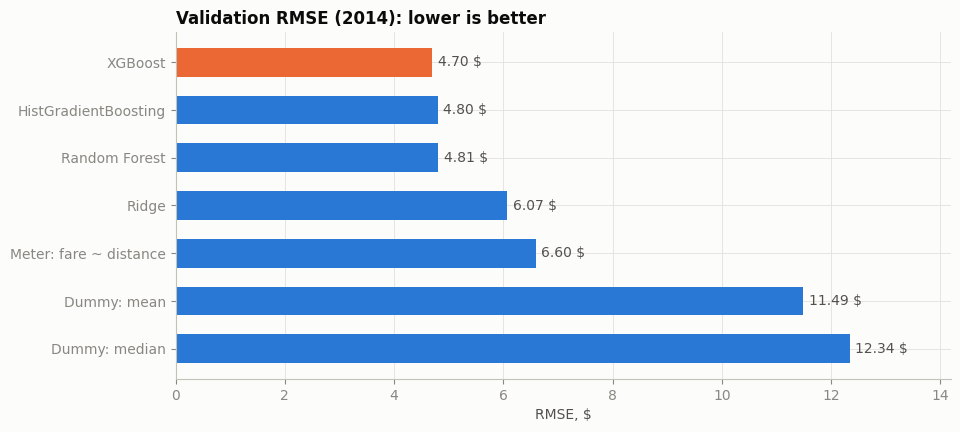

Best model on validation: XGBoost


In [29]:
fig, ax = plt.subplots(figsize=(10, 4.5))
order = comparison.sort_values('RMSE', ascending=False)
best_name = comparison.index[0]
colors = [ORANGE if name == best_name else BLUE for name in order.index]
bars = ax.barh(order.index, order['RMSE'], color=colors, height=0.6)
ax.bar_label(bars, fmt='%.2f $', padding=4, color=INK_2)
ax.set(title='Validation RMSE (2014): lower is better', xlabel='RMSE, $')
ax.set_xlim(0, order['RMSE'].max() * 1.15)
plt.show()
print('Best model on validation:', best_name)

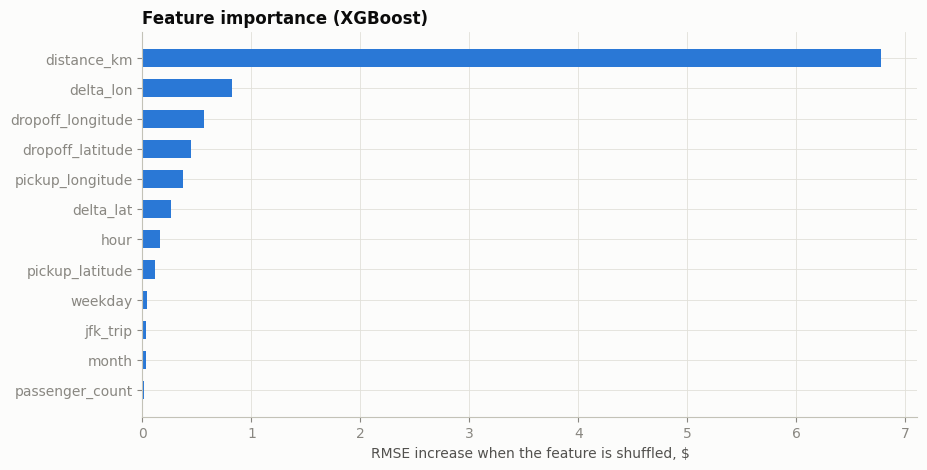

In [30]:
# Which features matter to the best model?
perm = permutation_importance(fitted[best_name], X_valid, y_valid,
                              scoring='neg_root_mean_squared_error',
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
importance = (pd.Series(perm.importances_mean, index=FEATURES)
              .sort_values(ascending=False).head(12)[::-1])

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(importance.index, importance.values, color=BLUE, height=0.6)
ax.set(title=f'Feature importance ({best_name})', xlabel='RMSE increase when the feature is shuffled, $')
plt.show()

### How much do the new features add?

I train the best configuration on the original columns alone and compare it with the full set.

In [31]:
feature_sets = {
    'original columns only': BASE_FEATURES,
    'original + new features': FEATURES,
}
fe_results = {}
for name, cols in feature_sets.items():
    model = clone(fitted[best_name]).fit(X_train[cols], y_train)
    fe_results[name] = {'features': len(cols), **score(y_valid, model.predict(X_valid[cols]))}
fe_results = pd.DataFrame(fe_results).T
fe_results['features'] = fe_results['features'].astype(int)
fe_results

,features,RMSE,MAE,R2
original columns only,5,5.650,2.746,0.748
original + new features,15,4.700,2.002,0.826


**Validation summary**

* Constants are useless: RMSE 11.5–12.3 dollars, R² below zero.
* The "meter" (fare from distance alone) is already 43% better than the dummy.
* Ridge beats the meter on RMSE but loses on MAE: a linear model does not describe the steps in the tariff.
* Trees give a large jump: RMSE around 4.7–4.8 dollars, MAE around 2 dollars.
* **The best model is XGBoost:** RMSE 4.70 dollars, MAE 2.00 dollars, R² 0.826 — 59% better than the dummy.
* **The new features paid off.** Without them the same model is noticeably worse: RMSE 5.65 against 4.70 dollars.
* The most important feature is distance, followed by `delta_lon`, the coordinates, `delta_lat` and the hour.

## 13. Final forecast on the test set

In [32]:
X_full = pd.concat([X_train, X_valid])
y_full = pd.concat([y_train, y_valid])

final_model = clone(fitted[best_name]).fit(X_full, y_full)
final_dummy = DummyRegressor(strategy='mean').fit(X_full, y_full)
final_meter = LinearRegression().fit(X_full[['distance_km']], y_full)

test_pred = final_model.predict(X_test)
test_results = pd.DataFrame({
    'Dummy: mean': score(y_test, final_dummy.predict(X_test)),
    'Meter: fare ~ distance': score(y_test, final_meter.predict(X_test[['distance_km']])),
    best_name: score(y_test, test_pred),
}).T
test_results['RMSE better than dummy, %'] = (1 - test_results['RMSE']
                                             / test_results.loc['Dummy: mean', 'RMSE']) * 100
test_results

,RMSE,MAE,R2,"RMSE better than dummy, %"
Dummy: mean,10.916,6.592,-0.029,0.000
Meter: fare ~ distance,5.345,2.902,0.753,51.033
XGBoost,3.837,1.895,0.873,64.848


In [33]:
# Save the forecast for the test set
predictions = pd.DataFrame({
    'key': test['key'],
    'pickup_datetime': test['pickup_datetime'],
    'fare_amount': y_test,
    'predicted_fare': test_pred.round(2),
})
predictions.to_csv('../data/nyc_taxi_test_predictions.csv', index=False)
predictions.head()

,key,pickup_datetime,fare_amount,predicted_fare
0,2015-06-21 21:46:34.0000001,2015-06-21 17:46:34,22.540,20.730
1,2015-01-11 03:15:38.0000001,2015-01-10 22:15:38,58.000,25.780
2,2015-03-12 08:08:38.0000001,2015-03-12 04:08:38,4.500,5.790
3,2015-04-12 10:19:05.0000001,2015-04-12 06:19:05,11.500,11.870
4,2015-05-12 23:51:42.0000007,2015-05-12 19:51:42,5.000,5.240


## 14. Error analysis on the test set

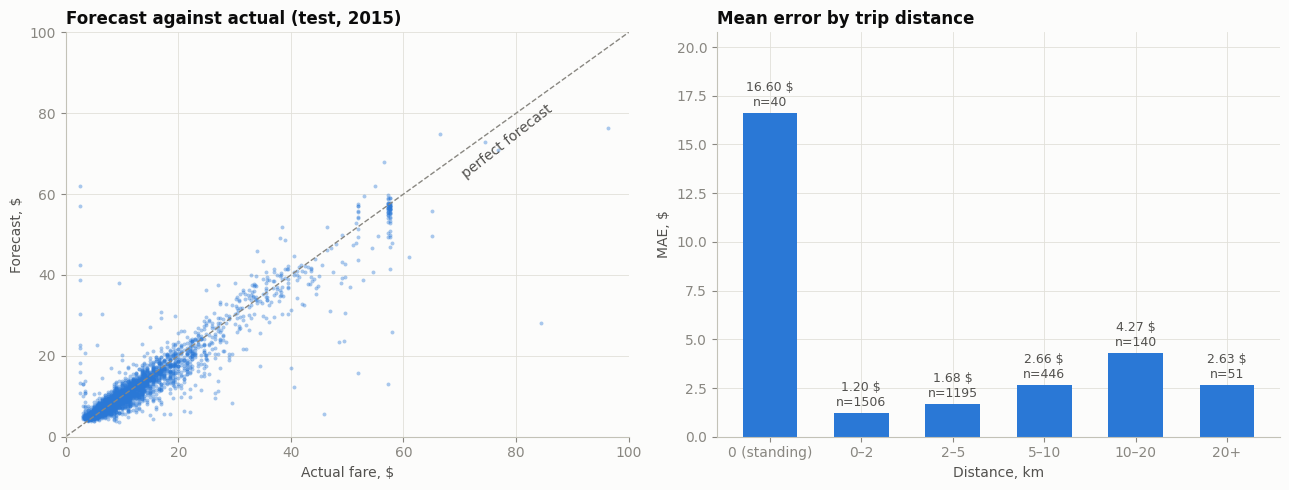

In [34]:
errors = test.assign(pred=test_pred, abs_error=np.abs(test_pred - y_test))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_test, test_pred, s=8, alpha=0.4, color=BLUE, linewidths=0)
axes[0].plot([0, 100], [0, 100], color=MUTED, linestyle='--', linewidth=1)
axes[0].text(70, 64, 'perfect forecast', color=INK_2, rotation=38)
axes[0].set(title='Forecast against actual (test, 2015)', xlabel='Actual fare, $',
            ylabel='Forecast, $', xlim=(0, 100), ylim=(0, 100))

bins = [-0.01, 0.1, 2, 5, 10, 20, 200]
labels = ['0 (standing)', '0–2', '2–5', '5–10', '10–20', '20+']
by_dist = (errors.assign(bucket=pd.cut(errors['distance_km'], bins=bins, labels=labels))
           .groupby('bucket', observed=True)
           .agg(trips=('abs_error', 'size'), MAE=('abs_error', 'mean')))
bars = axes[1].bar(by_dist.index.astype(str), by_dist['MAE'], color=BLUE, width=0.6)
axes[1].bar_label(bars, labels=[f'{m:.2f} $\nn={n}' for m, n in zip(by_dist['MAE'], by_dist['trips'])],
                  padding=3, color=INK_2, fontsize=9)
axes[1].set(title='Mean error by trip distance', xlabel='Distance, km', ylabel='MAE, $')
axes[1].set_ylim(0, by_dist['MAE'].max() * 1.25)

plt.tight_layout()
plt.show()

In [35]:
# How much of the RMSE comes from trips with zero distance
zero = errors['distance_km'] < 0.1
sq_err = (errors['pred'] - errors['fare_amount']) ** 2
print(f'Trips with zero distance: {zero.sum()} ({zero.mean():.1%} of the test set)')
print(f'Their share of the sum of squared errors: {sq_err[zero].sum() / sq_err.sum():.1%}')
print(f'RMSE without them: {sq_err[~zero].mean() ** 0.5:.3f} $ (with them: {sq_err.mean() ** 0.5:.3f} $)')

Trips with zero distance: 40 (1.2% of the test set)
Their share of the sum of squared errors: 41.6%
RMSE without them: 2.949 $ (with them: 3.837 $)


**Where does the model get it wrong?**

* On ordinary trips up to 5 km the mean error is 1.2–1.7 dollars — one or two clicks of the meter.
* On long trips the error is larger: about 4.3 dollars at 10–20 km.
* **The main source of error is trips with zero distance.** They are 1.2% of the test set but 42% of the squared error. Without them the RMSE would be 2.95 dollars instead of 3.84.
* The other misses are JFK trips with a non-standard fare: waiting time, stops, tolls.

## 15. Conclusions

**Result on the test set (2015)**

* Dummy (mean fare): RMSE 10.92 dollars, MAE 6.59 dollars.
* The "meter" (fare from distance): RMSE 5.35 dollars, MAE 2.90 dollars.
* **XGBoost: RMSE 3.84 dollars, MAE 1.90 dollars, R² 0.873** — 65% better than the dummy.

The typical error of the model is about 1.9 dollars against a median trip fare of 9.5 dollars.

The test metrics are even better than the validation ones: the final model was refitted on the fresh 2014 data, and judging by the dummy the test period contains fewer rare outliers. What matters more is that the advantage over the dummy is stable — 59% on validation and 65% on test.

**Why RMSE.** The metric is measured in dollars and punishes large misses harder: one 20-dollar error is worse than many 1-dollar ones. RMSE is twice MAE here, which means most of the error comes from a few anomalous trips.

**Is machine learning needed? Yes.**

* The dummy is useless: the same price for a two-block ride and for an airport trip, with R² below zero.
* The simple rule "drop charge plus price per km" is twice as good as the dummy, but it knows nothing about the JFK tariff, the 2012 increase or morning traffic.
* XGBoost improves on that rule by another 28% on RMSE and 35% on MAE, because it finds the non-linear dependencies itself.

But machine learning is not all-powerful: the fare of trips with zero distance cannot be predicted from this data.

**What could be improved**

* Add distances to LaGuardia and Newark airports and to Midtown Manhattan: in a trial run a wider feature set was about 2% better.
* Use the trip duration and the real route, the weather and public holidays.
* Train on more data: this is 50 thousand trips out of 55 million.
* Retrain the model after every tariff change.